<a href="https://colab.research.google.com/github/dmunsyzbaev-dot/coffee/blob/main/1DM_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# №1 зертханалық жұмыс — CRISP-DM және талдау ортасын дайындау


## 1-тапсырма. Ортаны дайындау (1–5 код)

In [1]:
!pip -q install pyarrow openpyxl seaborn scipy statsmodels scikit-learn jupyterlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 59.1 MB/s eta 0:00:00


In [2]:
import os, sys, platform, subprocess, time, json, pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display
SEED=42
np.random.seed(SEED)
print("Python:",sys.version.split()[0],"Платформа:",platform.platform())

Python: 3.13.16 Платформа: Linux-6.6.122+-x86_64-with-glibc2.39


In [3]:
for folder in ["data/raw","data/processed","notebooks","reports","src"]:
    os.makedirs(folder,exist_ok=True)
print("Жоба қалталары:", [p for p in pathlib.Path(".").iterdir() if p.is_dir() and p.name in ("data","notebooks","reports","src")])

Жоба қалталары: [PosixPath('src'), PosixPath('notebooks'), PosixPath('data'), PosixPath('reports')]


In [4]:
with open("requirements.txt","w") as f:
    subprocess.run([sys.executable,"-m","pip","freeze"],stdout=f,check=True)
print("requirements.txt жолдары:",len(open("requirements.txt").readlines()))

requirements.txt жолдары: 654


In [5]:
with open(".gitignore","w") as f:
    f.write("__pycache__/\n.ipynb_checkpoints/\n.env\n*.pyc\ndata/raw/\ndata/processed/\n")
print(open(".gitignore").read())
print("Git репозиторийін жариялау: Colab-тың File > Save a copy in GitHub командасын қолданыңыз.")

__pycache__/
.ipynb_checkpoints/
.env
*.pyc
data/raw/
data/processed/

Git репозиторийін жариялау: Colab-тың File > Save a copy in GitHub командасын қолданыңыз.


**Түсіндірме:** Құрылым жасалды, тәуелділіктер сақталды, құпия файлдар Git-тен жасырылды. GitHub-қа нақты жариялау аккаунтқа кіруді талап етеді.

## 2-тапсырма. CRISP-DM алты кезеңі (6–9 код)

In [6]:
stages=[("Business Understanding","Мақсат пен бизнес-сұрақты анықтау","Мәселе сипаттамасы, KPI"),("Data Understanding","Дерек көзін, сапасын зерттеу","Бастапқы EDA және деректер паспорты"),("Data Preparation","Тазалау, біріктіру, белгілерді таңдау","Дайын деректер жиыны"),("Modeling","Әдістерді таңдау, модель құру","Модель және параметрлер"),("Evaluation","Модельді бизнес мақсатпен салыстыру","Метрикалар мен шешім"),("Deployment","Нәтижені қолданысқа енгізу","Есеп, API немесе дашборд")]
crisp=pd.DataFrame(stages,columns=["Кезең","Мазмұны","Артефакт"]);display(crisp)

,Кезең,Мазмұны,Артефакт
0,Business Understanding,Мақсат пен бизнес-сұрақты анықтау,"Мәселе сипаттамасы, KPI"
1,Data Understanding,"Дерек көзін, сапасын зерттеу",Бастапқы EDA және деректер паспорты
2,Data Preparation,"Тазалау, біріктіру, белгілерді таңдау",Дайын деректер жиыны
3,Modeling,"Әдістерді таңдау, модель құру",Модель және параметрлер
4,Evaluation,Модельді бизнес мақсатпен салыстыру,Метрикалар мен шешім
5,Deployment,Нәтижені қолданысқа енгізу,"Есеп, API немесе дашборд"


In [7]:
crisp.to_csv("reports/crisp_dm.csv",index=False,encoding="utf-8-sig");print("Сақталды: reports/crisp_dm.csv")

Сақталды: reports/crisp_dm.csv


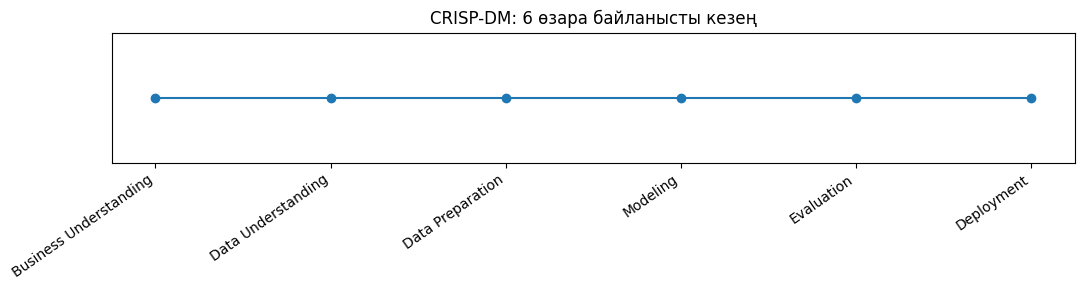

In [8]:
plt.figure(figsize=(11,3));plt.plot(range(1,7),[1]*6,"o-");plt.xticks(range(1,7),crisp["Кезең"],rotation=35,ha="right");plt.yticks([]);plt.title("CRISP-DM: 6 өзара байланысты кезең");plt.tight_layout();plt.show()

In [9]:
print("CRISP-DM циклді: бағалау кезінде мақсатқа жетпесек, дайындыққа немесе бизнес-мәселеге қайта ораламыз.")

CRISP-DM циклді: бағалау кезінде мақсатқа жетпесек, дайындыққа немесе бизнес-мәселеге қайта ораламыз.


## 3-тапсырма. Бизнес-мәселе және 7 зерттеу сұрағы (10–14 код)
**Мәселе:** халықтың табыс деңгейіне байланысты сипаттамаларды зерттеу. **Мақсат:** табыс санатымен байланысты белгілерді анықтау. Бұл себеп-салдарлық қорытынды емес.

In [10]:
questions=[("Жас пен табыс санаты байланысты ма?","Топтық үлестердің айырмасы","Топтау, график"),("Білім деңгейі бойынша айырмашылық бар ма?","Әр деңгей үшін үлес","Crosstab"),("Жұмыс сағаты табысқа қалай байланысты?","Медиана айырмасы","Boxplot"),("Кәсіп санаттары бойынша айырмашылық бар ма?","Әр кәсіп үшін үлес","Groupby"),("Отбасылық жағдайға қарай үлес өзгере ме?","Топтық пайыз","Crosstab"),("Капитал өсімі мен табыс арасында байланыс бар ма?","Медиана және корреляция","Корреляция"),("Деректер сапасы жеткілікті ме?","Бос мәндер үлесі","Сапа аудиті")]
qdf=pd.DataFrame(questions,columns=["Зерттеу сұрағы","Табыс өлшемі","Талдау әдісі"]);display(qdf)

,Зерттеу сұрағы,Табыс өлшемі,Талдау әдісі
0,Жас пен табыс санаты байланысты ма?,Топтық үлестердің айырмасы,"Топтау, график"
1,Білім деңгейі бойынша айырмашылық бар ма?,Әр деңгей үшін үлес,Crosstab
2,Жұмыс сағаты табысқа қалай байланысты?,Медиана айырмасы,Boxplot
3,Кәсіп санаттары бойынша айырмашылық бар ма?,Әр кәсіп үшін үлес,Groupby
4,Отбасылық жағдайға қарай үлес өзгере ме?,Топтық пайыз,Crosstab
5,Капитал өсімі мен табыс арасында байланыс бар ма?,Медиана және корреляция,Корреляция
6,Деректер сапасы жеткілікті ме?,Бос мәндер үлесі,Сапа аудиті


In [11]:
qdf.to_csv("reports/research_questions.csv",index=False,encoding="utf-8-sig");print("7 сұрақ сақталды")

7 сұрақ сақталды


In [19]:
print("Негізгі KPI: табысы >50K тобының үлесі; қосымша KPI: топтар арасындағы айырма (пайыздық пункт).")

Негізгі KPI: табысы >50K тобының үлесі; қосымша KPI: топтар арасындағы айырма (пайыздық пункт).


In [20]:
print("Шектеу: Adult жиыны АҚШ-тың тарихи деректеріне негізделген; нәтижені Қазақстанға тікелей көшіруге болмайды.")

Шектеу: Adult жиыны АҚШ-тың тарихи деректеріне негізделген; нәтижені Қазақстанға тікелей көшіруге болмайды.


In [21]:
print("Success criteria: барлық 7 сұрақ бойынша есептелетін өлшем мен кемінде бір дәлелді кесте немесе график беру.")

Success criteria: барлық 7 сұрақ бойынша есептелетін өлшем мен кемінде бір дәлелді кесте немесе график беру.


## 4-тапсырма. Деректермен алғашқы танысу (15–20 код)
OpenML интернеттен жүктеледі; желі болмаса файлды Colab-қа жүктеп, `data/raw/dataset.csv` орнына қойыңыз.

In [12]:
from sklearn.datasets import fetch_openml
try:
    adult=fetch_openml(data_id=1590,as_frame=True,parser="auto")
    df=adult.frame.copy()
    df.to_csv("data/raw/dataset.csv",index=False)
    print("OpenML жүктелді:",df.shape)
except Exception as e:
    if os.path.exists("data/raw/dataset.csv"):
        df=pd.read_csv("data/raw/dataset.csv");print("Жергілікті CSV оқылды")
    else:
        raise RuntimeError("OpenML қолжетімсіз. data/raw/dataset.csv файлын жүктеңіз") from e

OpenML жүктелді: (48842, 15)


In [13]:
df=pd.read_csv("data/raw/dataset.csv");print("Өлшем:",df.shape);assert df.shape[0]>=5000 and df.shape[1]>=10

Өлшем: (48842, 15)


In [14]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       46043 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      46033 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  47985 non-null  object
 14  class           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 26.4 MB


In [15]:
display(df.head(10))

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K
6,29,NaN,227026,HS-grad,9,Never-married,NaN,Unmarried,Black,Male,0,0,40,United-States,<=50K
7,63,Self-emp-not-inc,104626,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,3103,0,32,United-States,>50K
8,24,Private,369667,Some-college,10,Never-married,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
9,55,Private,104996,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,10,United-States,<=50K


In [16]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,46043,8,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,46033,14,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
print("Бос мәндер:\n", df.isna().sum().sort_values(ascending=False).head(15))
print("Қайталанатын жолдар:", df.duplicated().sum())

Бос мәндер:
 occupation        2809
workclass         2799
native-country     857
fnlwgt               0
education            0
education-num        0
age                  0
marital-status       0
relationship         0
sex                  0
race                 0
capital-gain         0
capital-loss         0
hours-per-week       0
class                0
dtype: int64
Қайталанатын жолдар: 52


**Түсіндірме:** Жол саны, баған типтері, негізгі статистика, бос мәндер және қайталанулар тексерілді. Есеп нақты орындалған кезде шығатын сандарға негізделеді.

## 5-тапсырма. Деректер сөздігі (21–25 код)

In [24]:
dictionary=pd.DataFrame({"column":df.columns,"dtype":df.dtypes.astype(str).values,"unique_count":[df[c].nunique(dropna=True) for c in df],"missing_count":[df[c].isna().sum() for c in df]});display(dictionary)

,column,dtype,unique_count,missing_count
0,age,int64,74,0
1,workclass,object,8,2799
2,fnlwgt,int64,28523,0
3,education,object,16,0
4,education-num,int64,16,0
5,marital-status,object,7,0
6,occupation,object,14,2809
7,relationship,object,6,0
8,race,object,5,0
9,sex,object,2,0


In [25]:
dictionary["scale"]=["қатынастық" if pd.api.types.is_numeric_dtype(df[c]) else "номиналды" for c in df.columns];display(dictionary[["column","scale"]])

,column,scale
0,age,қатынастық
1,workclass,номиналды
2,fnlwgt,қатынастық
3,education,номиналды
4,education-num,қатынастық
5,marital-status,номиналды
6,occupation,номиналды
7,relationship,номиналды
8,race,номиналды
9,sex,номиналды


In [26]:
dictionary["possible_values"]=[f"{df[c].min()} ... {df[c].max()}" if pd.api.types.is_numeric_dtype(df[c]) else ", ".join(map(str,df[c].dropna().unique()[:5])) for c in df.columns]

In [27]:
descriptions={"age":"Жас","workclass":"Жұмыс беруші түрі","fnlwgt":"Іріктеме салмағы","education":"Білім деңгейі","education-num":"Білім жылдарының сандық коды","marital-status":"Отбасылық жағдай","occupation":"Мамандық","relationship":"Отбасылық рөлі","race":"Нәсіл санаты","sex":"Жыныс","capital-gain":"Капитал өсімі","capital-loss":"Капитал шығыны","hours-per-week":"Апталық жұмыс сағаты","native-country":"Туған ел","class":"Табыс санаты"};dictionary["description"]=[descriptions.get(c,"Деректер жиынындағы белгі; құжаттамадан нақтылау қажет") for c in df.columns];display(dictionary)

,column,dtype,unique_count,missing_count,scale,possible_values,description
0,age,int64,74,0,қатынастық,17 ... 90,Жас
1,workclass,object,8,2799,номиналды,"Private, Local-gov, Self-emp-not-inc, Federal-...",Жұмыс беруші түрі
2,fnlwgt,int64,28523,0,қатынастық,12285 ... 1490400,Іріктеме салмағы
3,education,object,16,0,номиналды,"11th, HS-grad, Assoc-acdm, Some-college, 10th",Білім деңгейі
4,education-num,int64,16,0,қатынастық,1 ... 16,Білім жылдарының сандық коды
5,marital-status,object,7,0,номиналды,"Never-married, Married-civ-spouse, Widowed, Di...",Отбасылық жағдай
6,occupation,object,14,2809,номиналды,"Machine-op-inspct, Farming-fishing, Protective...",Мамандық
7,relationship,object,6,0,номиналды,"Own-child, Husband, Not-in-family, Unmarried, ...",Отбасылық рөлі
8,race,object,5,0,номиналды,"Black, White, Asian-Pac-Islander, Other, Amer-...",Нәсіл санаты
9,sex,object,2,0,номиналды,"Male, Female",Жыныс


In [28]:
dictionary.to_csv("reports/data_dictionary.csv",index=False,encoding="utf-8-sig");print("Сақталды: reports/data_dictionary.csv");display(dictionary.head())

Сақталды: reports/data_dictionary.csv


,column,dtype,unique_count,missing_count,scale,possible_values,description
0,age,int64,74,0,қатынастық,17 ... 90,Жас
1,workclass,object,8,2799,номиналды,"Private, Local-gov, Self-emp-not-inc, Federal-...",Жұмыс беруші түрі
2,fnlwgt,int64,28523,0,қатынастық,12285 ... 1490400,Іріктеме салмағы
3,education,object,16,0,номиналды,"11th, HS-grad, Assoc-acdm, Some-college, 10th",Білім деңгейі
4,education-num,int64,16,0,қатынастық,1 ... 16,Білім жылдарының сандық коды


**Ескерту:** Өлшеу шкаласы автоматты түрде жуық белгіленді; `education-num` сияқты кодталған айнымалылардың шкаласын пәндік тұрғыдан қолмен нақтылау қажет.

## 6-тапсырма. Жадты оңтайландыру және форматтарды салыстыру (26–30 код)

In [29]:
before=df.memory_usage(deep=True).sum();optimized=df.copy();print("Бастапқы жад (MB):",round(before/1024**2,3))

Бастапқы жад (MB): 26.359


In [32]:
for c in optimized.select_dtypes(include="number"):
    optimized[c] = pd.to_numeric(optimized[c], downcast="integer" if pd.api.types.is_integer_dtype(optimized[c]) else "float")
print(optimized.select_dtypes(include="number").dtypes)

age                int8
fnlwgt            int32
education-num      int8
capital-gain      int32
capital-loss      int16
hours-per-week     int8
dtype: object


In [33]:
for c in optimized.select_dtypes(include=["object", "string"]).columns:
    if optimized[c].nunique(dropna=False) / len(optimized) < 0.5:
        optimized[c] = optimized[c].astype("category")
print(optimized.dtypes)

age                   int8
workclass         category
fnlwgt               int32
education         category
education-num         int8
marital-status    category
occupation        category
relationship      category
race              category
sex               category
capital-gain         int32
capital-loss         int16
hours-per-week        int8
native-country    category
class             category
dtype: object


In [34]:
after=optimized.memory_usage(deep=True).sum();print(f"Жад: {before/1024**2:.2f} -> {after/1024**2:.2f} MB; үнем: {(before-after)/before*100:.2f}%")
optimized.to_parquet("data/processed/dataset.parquet",index=False)

Жад: 26.36 -> 1.03 MB; үнем: 96.08%


In [35]:
csv_path="data/raw/dataset.csv";pq_path="data/processed/dataset.parquet"
t0=time.perf_counter();a=pd.read_csv(csv_path);csv_time=time.perf_counter()-t0
t0=time.perf_counter();b=pd.read_parquet(pq_path);pq_time=time.perf_counter()-t0
comparison=pd.DataFrame({"Формат":["CSV","Parquet"],"Көлемі (MB)":[os.path.getsize(csv_path)/1024**2,os.path.getsize(pq_path)/1024**2],"Оқу уақыты (сек)":[csv_time,pq_time]});display(comparison);comparison.to_csv("reports/format_comparison.csv",index=False)

## Қорытынды
CRISP-DM кезеңдері мен артефактілері сипатталды; 7 зерттеу сұрағы қойылды; деректер жүктеліп, зерттелді; сөздік автоматты жасалды; жад пен CSV/Parquet салыстырылды. **Нақты пайыздар мен уақыттар кодты іске қосқанда анықталады.**

## Бақылау сұрақтарына жауап
**1. Неге CRISP-DM циклді?** Алты кезең: бизнес-мәселені түсіну, деректерді түсіну, дайындау, модельдеу, бағалау, енгізу. Бағалау нәтижесі қанағаттандырмаса, алдыңғы кезеңдерге ораламыз.

**2. Өлшеу шкалалары:** номиналды — санат, жиілік/мода; реттік — рет, медиана/ранг; интервалдық — айырма мағыналы, нөл шартты (°C); қатынастық — нақты нөл, қатынас және орташа мән мағыналы.

**3. Қайталанғыштық:** бастапқы деректерді сақтап, random seed бекіту, кітапхана нұсқаларын жазу, кодты Git-те сақтау, барлық ұяшықты ретімен қайта орындау.